## Seleção de características e classificação

*Kalil Nege — RA 2409020 · OPT098 - Tópicos Especiais em Sistemas de Computação (Prof. Dr. Rodrigo Hübner)*

Com 40 alvos, o acaso é **2,5%**. Etapas:

1. **Voto** (sem treino), como no `classifier_per_freq.ipynb`: o alvo previsto é a frequência com o maior valor da característica;
2. **SVM** sobre as características do notebook 03, comparando os grupos SSVEP, ritmos e fusão;
3. Seleção de características com **RFE**.

#### Validação

- **Por bloco**: um modelo por participante, treinado em 3 blocos e testado no que sobrou, repetindo para os 4 blocos. Cada bloco tem um ensaio por alvo, então o teste nunca vê um ensaio do treino.
- **Entre participantes**: `GroupKFold` (5 partições) agrupando por participante. O modelo é testado em pessoas que ele nunca viu.

O `StandardScaler` e o `RFE` ficam dentro do *pipeline*, então são ajustados só com o treino de cada partição.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import warnings
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.feature_selection import RFE
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, cross_val_predict

warnings.filterwarnings('ignore')
SEMENTE = 0

F = np.load('dados/caracteristicas.npy')
meta = np.load('dados/meta.npy')
NOMES = list(np.load('dados/nomes_caracteristicas.npy'))
suj, bloco, y = meta[:, 0].astype(int), meta[:, 1].astype(int), meta[:, 2].astype(int)
SUJEITOS = np.unique(suj)

IDX = {t: np.arange(40 * k, 40 * (k + 1)) for k, t in enumerate(('snr_e', 'snr_l', 'cca'))}
IDX_SSVEP = np.arange(120)
IDX_RITMOS = np.arange(120, F.shape[1])
IDX_TUDO = np.arange(F.shape[1])
print(F.shape, '|', len(SUJEITOS), 'participantes')


def resumo(nome, acerto):
    acur = np.array([acerto[suj == s].mean() for s in SUJEITOS])
    print(f'{nome:<30} {100 * acur.mean():5.1f} ± {100 * acur.std() / np.sqrt(len(acur)):4.1f} %')
    return acur

(11200, 127) | 70 participantes


### 1. Voto (sem treino)

In [2]:
for t, idx in IDX.items():
    resumo(f'voto {t}', F[:, idx].argmax(axis=1) == y)

voto snr_e                      23.4 ±  2.3 %
voto snr_l                      45.5 ±  3.2 %
voto cca                        69.2 ±  2.8 %


O SNR de banda estreita vai mal no voto porque, com 2 s de sinal, a resolução real é de 0,5 Hz: o preenchimento com zeros cria pontos a cada 0,2 Hz, mas os "vizinhos" a ±0,2 e ±0,4 Hz ficam dentro do próprio pico. É uma limitação da métrica com janela curta.

### 2. SVM

In [3]:
def svm(n=None):
    etapas = [StandardScaler()]
    if n is not None:
        etapas.append(RFE(LinearSVC(C=0.1, dual=False, random_state=SEMENTE), n_features_to_select=n, step=0.1))
    etapas.append(SVC(C=10., random_state=SEMENTE))
    return make_pipeline(*etapas)


def por_bloco(modelo, idx):
    acerto = np.zeros(len(y), bool)
    for s in SUJEITOS:
        m = suj == s
        acerto[m] = cross_val_predict(modelo, F[m][:, idx], y[m], groups=bloco[m], cv=LeaveOneGroupOut()) == y[m]
    return acerto


def entre(modelo, idx):
    return cross_val_predict(modelo, F[:, idx], y, groups=suj, cv=GroupKFold(n_splits=5)) == y


GRUPOS = (('SSVEP', IDX_SSVEP), ('Ritmos', IDX_RITMOS), ('Fusão', IDX_TUDO))
for g, idx in GRUPOS:
    resumo(f'SVM {g} (por bloco)', por_bloco(svm(), idx))
for g, idx in GRUPOS:
    resumo(f'SVM {g} (entre participantes)', entre(svm(), idx))

SVM SSVEP (por bloco)           48.8 ±  3.0 %


SVM Ritmos (por bloco)           3.0 ±  0.2 %


SVM Fusão (por bloco)           47.9 ±  2.9 %


SVM SSVEP (entre participantes)  69.9 ±  2.7 %


SVM Ritmos (entre participantes)   2.8 ±  0.2 %


SVM Fusão (entre participantes)  69.9 ±  2.7 %


### 3. Seleção com RFE

Como sugerido no `beta_ml.ipynb`, aplico o `RFE` variando `n_features_to_select`. O ranqueamento usa um SVM linear (`LinearSVC`, que fornece os pesos `coef_`) e o classificador final é um SVM RBF.

  5 características -> por bloco  15.9 % | entre participantes  17.9 %


 10 características -> por bloco  26.4 % | entre participantes  28.6 %


 20 características -> por bloco  40.9 % | entre participantes  45.5 %


 40 características -> por bloco  53.2 % | entre participantes  70.6 %


 80 características -> por bloco  52.9 % | entre participantes  71.0 %


127 características -> por bloco  47.9 % | entre participantes  69.9 %


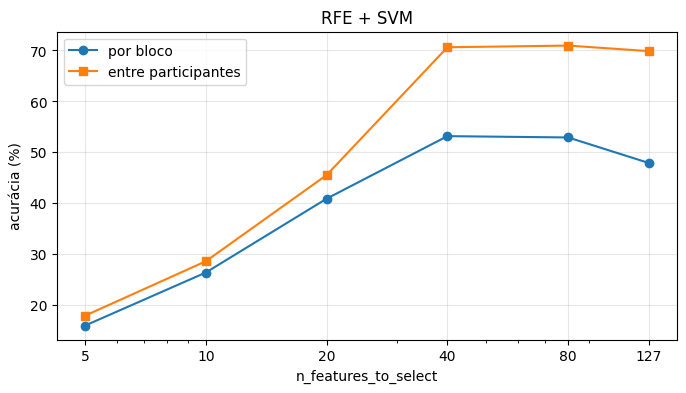

In [4]:
n_carac = [5, 10, 20, 40, 80, 127]
curva_bloco, curva_entre = [], []
for n in n_carac:
    curva_bloco.append(100 * por_bloco(svm(n), IDX_TUDO).mean())
    curva_entre.append(100 * entre(svm(n), IDX_TUDO).mean())
    print(f'{n:>3} características -> por bloco {curva_bloco[-1]:5.1f} % | entre participantes {curva_entre[-1]:5.1f} %')

rcParams['figure.figsize'] = [8., 4.]
plt.plot(n_carac, curva_bloco, 'o-', label='por bloco')
plt.plot(n_carac, curva_entre, 's-', label='entre participantes')
plt.xscale('log'); plt.xticks(n_carac, n_carac)
plt.xlabel('n_features_to_select'); plt.ylabel('acurácia (%)'); plt.title('RFE + SVM')
plt.grid(alpha=.3); plt.legend(); plt.show()

In [5]:
rfe = make_pipeline(StandardScaler(), RFE(LinearSVC(C=0.1, dual=False, random_state=SEMENTE),
                                          n_features_to_select=20, step=0.1)).fit(F, y)
mantidas = np.array(NOMES)[rfe[-1].support_]
tipos, qtd = np.unique([m.rsplit('_', 1)[0] if m in NOMES[:120] else 'ritmo' for m in mantidas], return_counts=True)
print('20 características mantidas:', {str(t): int(q) for t, q in zip(tipos, qtd)})

20 características mantidas: {'cca': 20}


### Conclusões

- O melhor resultado foi o **voto pelo CCA** (69,2%), que não usa treino nenhum. Com 40 alvos e 2 s de sinal, ele fica muito acima do acaso (2,5%).
- O **SVM por bloco** ficou bem abaixo (48,8%). Cada modelo é treinado com só 3 exemplos por alvo para 120 características, então ele aprende menos do que o CCA já entrega sozinho. Com o RFE em 40 características ele melhora um pouco (53,2%).
- **Entre participantes**, o SVM chega a 69,9% (70,6% com RFE), praticamente igual ao voto CCA. Aqui o treino tem cerca de 224 exemplos por alvo, e como o CCA compara o sinal com senos e cossenos, o que o modelo aprende ("a coluna mais alta é o alvo") vale para qualquer pessoa.
- Com 20 características, o RFE mantém **só correlações CCA**.
- Os **ritmos** ficam no acaso (cerca de 3%), e juntá-los ao SSVEP não melhora nada. Assim como no AVI, beta e TBR não indicam para onde a pessoa olha.